# 08 — Explainable AI (FD001)

**Project:** Predictive Intelligence · **Phase 7**

## Objective

A maintenance manager told "this engine has about 22 cycles left" will ask *why*. This notebook opens up the model and answers:

1. Which sensors does the model rely on overall?
2. For one engine, which measurements pushed its estimate up or down?
3. Why do two engines of the same age get very different predictions?
4. Is the model relying on patterns that make sense, given what notebooks 01–03 found in the data?
5. How stable are the explanations?

**Which model is explained.** The XGBoost model from notebook 05. Its accuracy is level with the best models so far, and for tree models SHAP values can be computed exactly and quickly. For neural networks they can only be approximated.

**What an explanation is and is not.** It describes how the *model* arrived at its number. It does not diagnose the engine. A sensor with a large contribution is one the model found useful for prediction; that is not proof that the quantity it measures is the cause of the wear.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

# SHAP looks for an optional notebook progress-bar widget; its absence is harmless.
warnings.filterwarnings("ignore", message="IProgress not found")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from xgboost import XGBRegressor

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src import config
from src.data.cmapss import SENSOR_INFO, add_training_rul, load_subset
from src.data.splits import engine_folds
from src.explainability.shap_explain import by_sensor, explain, kind_of, top_reasons
from src.features.build import build_tabular_features, cap_rul
from src.visualization import theme

theme.apply_theme()
pd.set_option("display.max_columns", 30)

train, test, test_rul = load_subset("FD001")
sensors = config.FD001_SENSORS
train_table, feature_columns = build_tabular_features(
    add_training_rul(train), sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
train_table["target"] = cap_rul(train_table["rul"], config.RUL_CAP)

test_table, _ = build_tabular_features(test, sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
test_last = test_table.groupby("engine_id").tail(1).merge(test_rul, on="engine_id").set_index("engine_id")

model = joblib.load(project_root / "models" / "fd001_xgboost.joblib")
test_last["predicted_rul"] = np.clip(model.predict(test_last[feature_columns]), 0, config.RUL_CAP)


def sensor_label(name: str) -> str:
    return f"{name.replace('sensor_', 'S')} · {SENSOR_INFO[name][0]}"

## 2. What SHAP does, in plain terms

Imagine the model's estimate as a bill to be split. The model starts from its **average prediction** across all the data it was trained on. For a particular engine, the final estimate is higher or lower than that average. SHAP divides the difference among the features: *this* feature moved the estimate down by 16 cycles, *that* one moved it up by 3, and so on.

The division follows a rule from game theory (Shapley values) that guarantees fairness in a specific sense: a feature's share is its average effect across all the orders in which features could be "revealed" to the model. Two properties matter for us:

- **The shares add up exactly.** Average prediction + all contributions = the model's prediction. Nothing is left unexplained and nothing is double-counted.
- **Units are cycles.** A contribution of −16 means "this feature made the estimate 16 cycles lower than it would otherwise be".

**When to use it.** For explaining individual predictions of a fixed model, and for summarising what a model depends on.

**When to be careful.** When features are strongly related, credit is shared between them somewhat arbitrarily. Our model has four features per sensor (current reading, 30-cycle average, 30-cycle variability, change from baseline), which are related by construction. We therefore **add up the four features of each sensor** and report one number per sensor. That total is much more stable than its parts.

First, the adding-up property is verified on real predictions.

In [2]:
# A fixed random sample of training rows describes the model's behaviour across all stages of life.
sample_rows = train_table.sample(3000, random_state=config.RANDOM_SEED)
contributions, average_prediction = explain(model, sample_rows[feature_columns])

reconstructed = average_prediction + contributions.sum(axis=1)
largest_gap = np.abs(reconstructed - model.predict(sample_rows[feature_columns])).max()

print(f"Model's average prediction (the starting point): {average_prediction:.1f} cycles")
print(f"Largest difference between 'average + contributions' and the model's output: {largest_gap:.5f} cycles")

Model's average prediction (the starting point): 86.9 cycles
Largest difference between 'average + contributions' and the model's output: 0.00027 cycles


The contributions reproduce the model's output to within rounding error, on all 3,000 rows.

## 3. Which sensors does the model rely on overall?

For each sensor we take the size of its total contribution (ignoring sign) and average it over the 3,000 rows. A value of 8 means that sensor moves the estimate by 8 cycles on average, in one direction or the other.

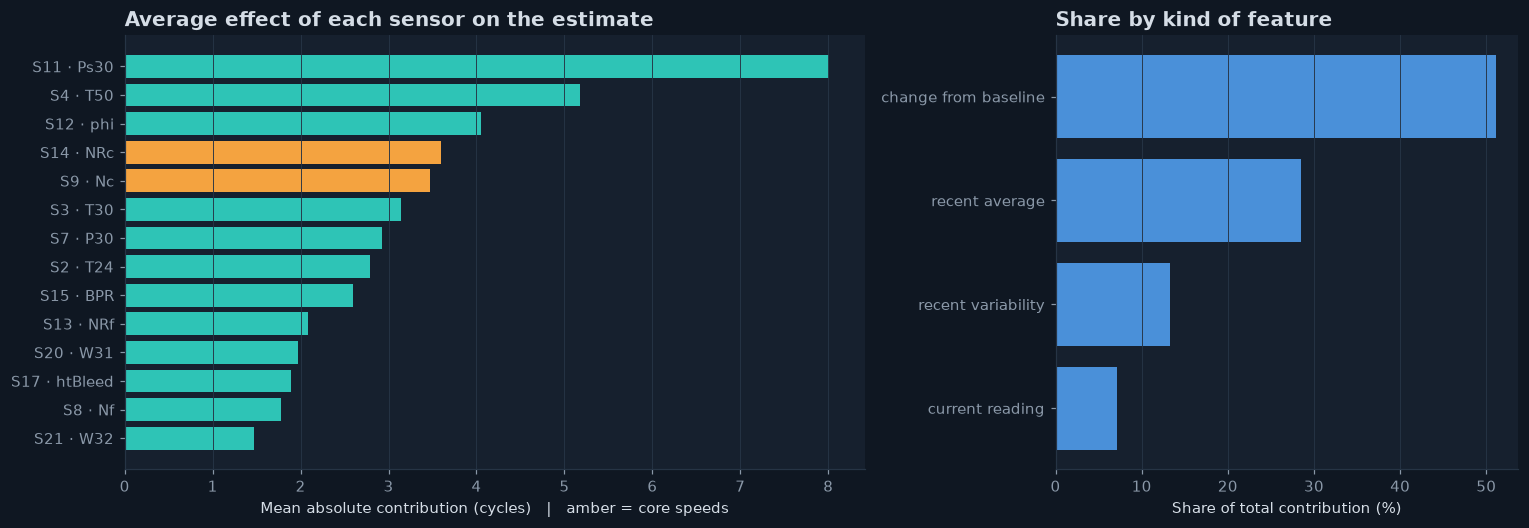

,sensor_11,sensor_4,sensor_12,sensor_14,sensor_9,sensor_3,sensor_7,sensor_2,sensor_15,sensor_13,sensor_20,sensor_17,sensor_8,sensor_21
mean |contribution| (cycles),8.000000,5.2,4.1,3.6,3.5,3.1,2.9,2.8,2.6,2.1,2.0,1.9,1.8,1.5
share (%),17.799999,11.5,9.0,8.0,7.7,7.0,6.5,6.2,5.8,4.6,4.4,4.2,4.0,3.3


In [3]:
sensor_contributions = by_sensor(contributions)
sensor_importance = sensor_contributions.abs().mean().sort_values(ascending=False)
importance_share = sensor_importance / sensor_importance.sum() * 100

feature_importance = contributions.abs().mean()
kind_share = feature_importance.groupby(kind_of).sum() / feature_importance.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={"width_ratios": [1.6, 1]})
bar_colors = [theme.AMBER if name in ("sensor_9", "sensor_14") else theme.TEAL for name in sensor_importance.index]
axes[0].barh([sensor_label(s) for s in sensor_importance.index], sensor_importance, color=bar_colors)
axes[0].invert_yaxis()
axes[0].set_title("Average effect of each sensor on the estimate")
axes[0].set_xlabel("Mean absolute contribution (cycles)   |   amber = core speeds")
axes[0].grid(axis="y", visible=False)

kind_share = kind_share.sort_values()
axes[1].barh(kind_share.index, kind_share, color=theme.BLUE)
axes[1].set_title("Share by kind of feature")
axes[1].set_xlabel("Share of total contribution (%)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

pd.DataFrame({"mean |contribution| (cycles)": sensor_importance, "share (%)": importance_share}).round(1).T

**Findings.**

- **S11 (Ps30, static pressure at the HPC outlet) is the model's main source**, moving the estimate by about 8 cycles on average, around 18% of the total. S4 (T50) and S12 (phi) follow.
- **No single sensor dominates.** The top sensor holds under a fifth of the total, and all fourteen contribute. The model is combining many weak signals, which is what notebook 03 said a good predictor has to do.
- **The model mostly uses "change from baseline"** (about half of all contribution) and the 30-cycle average (over a quarter). The single current reading accounts for only about 7%. The model has learned to trust slow, engine-relative signals over one noisy snapshot, which is the sensible strategy.
- **The core speeds S9 and S14 rank fourth and fifth.** These are the sensors whose direction differs between engines. Section 5 looks at how the model uses them.

### Does this match what the data showed?

Notebook 01 ranked sensors by how strongly they trend with RUL, without any model. If the model were relying on something unrelated to wear, the two rankings would disagree badly.

In [4]:
trend_strength = train_table[sensors].corrwith(train_table["rul"], method="spearman").abs()
comparison = pd.DataFrame({
    "rank by model reliance": sensor_importance.rank(ascending=False).astype(int),
    "rank by trend with RUL (notebook 01)": trend_strength.rank(ascending=False).astype(int),
}).sort_values("rank by model reliance")
comparison.index = [sensor_label(s) for s in comparison.index]

agreement = stats.spearmanr(sensor_importance[sensors], trend_strength[sensors])
print(f"Rank agreement between the two orderings (Spearman): {agreement.statistic:.2f}")
comparison.T

Rank agreement between the two orderings (Spearman): 0.32


,S11 · Ps30,S4 · T50,S12 · phi,S14 · NRc,S9 · Nc,S3 · T30,S7 · P30,S2 · T24,S15 · BPR,S13 · NRf,S20 · W31,S17 · htBleed,S8 · Nf,S21 · W32
rank by model reliance,1,2,3,4,5,6,7,8,9,10,11,12,13,14
rank by trend with RUL (notebook 01),1,2,3,14,13,10,4,9,5,12,7,8,11,6


**Findings.**

- **The top of both lists agrees.** S11, S4 and S12 lead the model's ranking and are also the three sensors with the strongest trend in the raw data.
- **Overall agreement is only moderate** (about 0.3). The main reason is S9 and S14: weak as a simple trend, but fourth and fifth for the model.
- That is not automatically a problem. A simple trend measure asks "does this sensor move the same way on every engine?". A tree model can use a sensor conditionally, in combination with others. But it is exactly the point to check, so the next sections look at *how* the model uses its top sensor and the core speeds.

## 4. Direction: does the model read the sensors the right way round?

From notebook 02 we know Ps30 (S11) *rises* as an engine wears. So a model reasoning sensibly should lower its estimate as "S11 change from baseline" grows. Each dot below is one of the 3,000 rows.

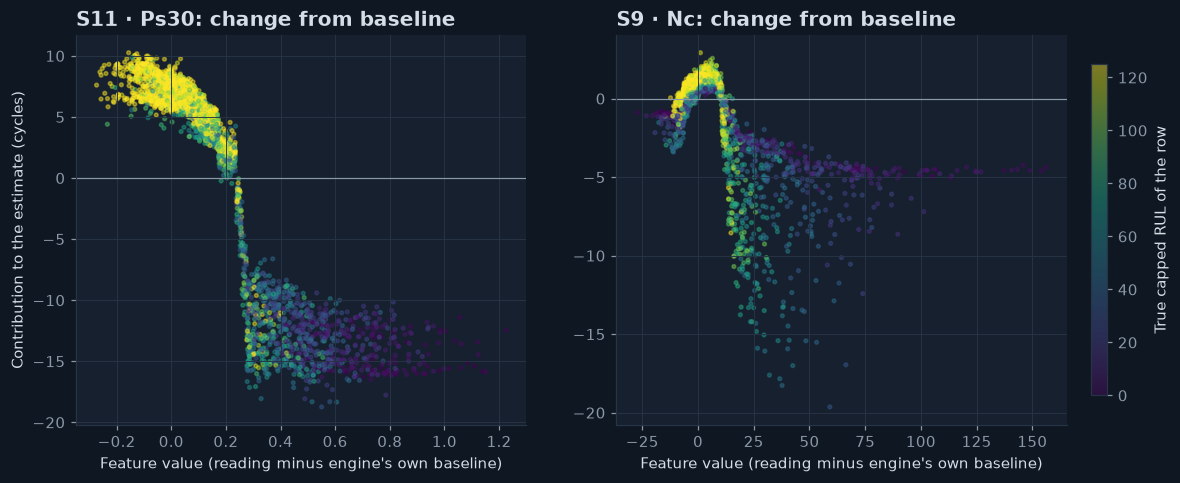

,lowest fifth,2nd,3rd,4th,highest fifth
sensor_11_delta,7.6,6.8,4.7,-5.1,-13.3
sensor_9_delta,0.0,1.0,1.3,0.8,-5.9


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, feature in zip(axes, ["sensor_11_delta", "sensor_9_delta"]):
    ax.scatter(sample_rows[feature], contributions[feature], s=6, alpha=0.45,
               c=sample_rows["target"], cmap="viridis", vmin=0, vmax=config.RUL_CAP)
    ax.axhline(0, color=theme.MUTED, linewidth=0.8)
    ax.set_title(f"{sensor_label(feature.replace('_delta', ''))}: change from baseline")
    ax.set_xlabel("Feature value (reading minus engine's own baseline)")
axes[0].set_ylabel("Contribution to the estimate (cycles)")
colorbar = fig.colorbar(axes[1].collections[0], ax=axes, shrink=0.85, pad=0.02)
colorbar.set_label("True capped RUL of the row")
plt.show()

direction_rows = {}
for feature in ["sensor_11_delta", "sensor_9_delta"]:
    fifths = pd.qcut(sample_rows[feature], 5, labels=["lowest fifth", "2nd", "3rd", "4th", "highest fifth"])
    direction_rows[feature] = contributions[feature].groupby(fifths, observed=True).mean()
pd.DataFrame(direction_rows).T.round(1)

**Findings.**

- **S11 is read the right way round.** While Ps30 sits at or near the engine's baseline, the feature *adds* about 5 to 8 cycles to the estimate. Once it has risen clearly above baseline, the contribution turns negative, reaching about −13 cycles in the highest fifth. The relationship is smooth and one-directional (rank correlation −0.93), matching the physical trend seen in the data.
- **S9 is used one-sidedly.** For four-fifths of the rows its contribution is close to zero. Only a *large rise* in core speed (roughly 13 rpm or more above baseline) pulls the estimate down, by about 6 cycles on average. A *fall* in core speed is essentially ignored.
- That matches notebook 02: about 70 of 100 engines show a rising core speed late in life, some strongly, while the rest drift slightly down. The model has learned "a big rise is a sign of wear; anything else tells me nothing", which is a reasonable reading of an inconsistent sensor.

So on both checks the model's behaviour is consistent with patterns independently found in the data. This raises confidence that it is not relying on an artefact. It does not prove the model is right for the right physical reasons.

## 5. Explaining individual engines

Now the question a maintenance manager would actually ask. We take two test engines that have been in service for **exactly the same number of cycles (121)**, yet receive very different estimates.

In [6]:
ENGINE_A, ENGINE_B = 54, 37   # same recorded history length, very different predictions

test_contributions, _ = explain(model, test_last[feature_columns])
test_sensor_contributions = by_sensor(test_contributions)

test_last.loc[[ENGINE_A, ENGINE_B], ["cycle", "predicted_rul", "true_rul"]].rename(
    columns={"cycle": "cycles recorded"}).round(1)

,cycles recorded,predicted_rul,true_rul
engine_id,,,
54,121,119.699997,97
37,121,21.600000,21


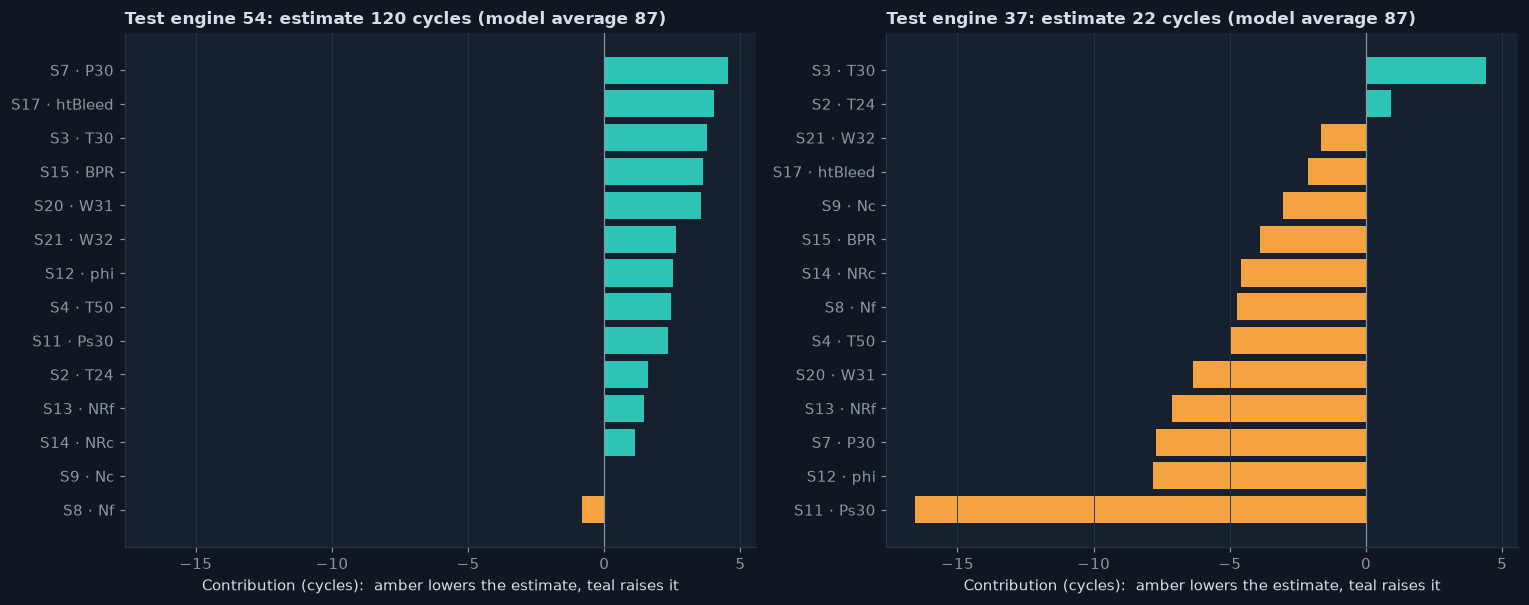

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharex=True)
for ax, engine_id in zip(axes, [ENGINE_A, ENGINE_B]):
    engine_contributions = test_sensor_contributions.loc[engine_id].sort_values()
    colors = [theme.AMBER if value < 0 else theme.TEAL for value in engine_contributions]
    ax.barh([sensor_label(s) for s in engine_contributions.index], engine_contributions, color=colors)
    ax.axvline(0, color=theme.MUTED, linewidth=0.8)
    ax.set_title(f"Test engine {engine_id}: estimate {test_last.loc[engine_id, 'predicted_rul']:.0f} cycles "
                 f"(model average {average_prediction:.0f})", fontsize=11)
    ax.set_xlabel("Contribution (cycles):  amber lowers the estimate, teal raises it")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

In [8]:
for engine_id in [ENGINE_A, ENGINE_B]:
    row = test_last.loc[engine_id]
    total = test_contributions.loc[engine_id].sum()
    print(f"Test engine {engine_id}: {average_prediction:.1f} (average) {total:+.1f} (all sensors) "
          f"= {average_prediction + total:.1f}   | true RUL {row['true_rul']:.0f}")
    for reason in top_reasons(test_contributions.loc[engine_id], count=4):
        print(f"   {reason['symbol']:8s} {reason['cycles']:+6.1f} cycles  ({reason['description']}, {reason['effect']})")
    print()

difference = (test_sensor_contributions.loc[ENGINE_B] - test_sensor_contributions.loc[ENGINE_A]).sort_values()
print("Sensors that account for most of the gap between the two engines (cycles):")
print(difference.head(5).round(1).rename(index=sensor_label).to_string())

Test engine 54: 86.9 (average) +32.8 (all sensors) = 119.7   | true RUL 97
   P30        +4.5 cycles  (Total pressure at HPC outlet, raises the estimate)
   htBleed    +4.0 cycles  (Bleed enthalpy, raises the estimate)
   T30        +3.8 cycles  (Total temperature at HPC outlet, raises the estimate)
   BPR        +3.6 cycles  (Bypass ratio, raises the estimate)

Test engine 37: 86.9 (average) -65.3 (all sensors) = 21.6   | true RUL 21
   Ps30      -16.6 cycles  (Static pressure at HPC outlet, lowers the estimate)
   phi        -7.8 cycles  (Ratio of fuel flow to Ps30, lowers the estimate)
   P30        -7.7 cycles  (Total pressure at HPC outlet, lowers the estimate)
   NRf        -7.1 cycles  (Corrected fan speed, lowers the estimate)

Sensors that account for most of the gap between the two engines (cycles):
S11 · Ps30   -18.9
S7 · P30     -12.2
S12 · phi    -10.3
S20 · W31     -9.9
S13 · NRf     -8.6


**Reading the two explanations.**

- **Engine 54** is estimated at about 120 cycles, well above the model's average of 87. Every sensor pushes the estimate *up* a little, none strongly. In plain words: all its measurements still sit close to where they were when the engine was new, so the model sees no sign of wear. Its true remaining life was 97 cycles.
- **Engine 37** is estimated at about 22 cycles. Here the sensors push *down*: Ps30 alone removes about 17 cycles, with the fuel-flow ratio, HPC outlet pressure and fan speed each removing 7 to 8 more. In plain words: several measurements have moved clearly away from this engine's own starting levels, in the directions associated with wear. Its true remaining life was 21 cycles.
- **Why the same age gives different answers:** the model does not use age at all (decision D-007). It responds to how far each engine's readings have drifted from its own baseline. Engine 37 has drifted; engine 54 has not.

**What we must not say.** These charts do not show that engine 37 has a pressure problem at the HPC outlet. They show that the model used the Ps30 reading as its strongest evidence. In the simulation the underlying fault is HPC degradation, which affects many sensors at once; the explanation points at the symptoms the model found most useful, not at a diagnosed component.

This structured output (`top_reasons`) is what the question-answering assistant will receive in Phase 10, so its explanations come from the model and are not invented.

## 6. How stable are the explanations?

An explanation is only worth giving if it does not change every time the model is retrained. We train five XGBoost models, each on a different 80 engines (the cross-validation folds from notebook 04), explain the same 3,000 rows with each, and compare the sensor rankings.

In [9]:
fold_importance = []
for train_rows, _ in engine_folds(train_table):
    fold_data = train_table.iloc[train_rows]
    fold_model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                              colsample_bytree=0.8, n_jobs=-1, random_state=config.RANDOM_SEED)
    fold_model.fit(fold_data[feature_columns], fold_data["target"])
    fold_contributions, _ = explain(fold_model, sample_rows[feature_columns])
    fold_importance.append(by_sensor(fold_contributions).abs().mean())

fold_importance = pd.DataFrame(fold_importance, index=[f"model {i}" for i in range(1, 6)])
fold_share = fold_importance.div(fold_importance.sum(axis=1), axis=0) * 100

pairwise = [stats.spearmanr(fold_importance.iloc[i], fold_importance.iloc[j]).statistic
            for i in range(5) for j in range(i + 1, 5)]
print(f"Agreement of sensor rankings between pairs of models: lowest {min(pairwise):.2f}, average {np.mean(pairwise):.2f}")
print("Top three sensors per model:")
for name, row in fold_importance.iterrows():
    print("  ", name, [sensor_label(s) for s in row.sort_values(ascending=False).index[:3]])

fold_share[sensor_importance.index].rename(columns=sensor_label).round(1)

Agreement of sensor rankings between pairs of models: lowest 0.56, average 0.77
Top three sensors per model:
   model 1 ['S11 · Ps30', 'S12 · phi', 'S14 · NRc']
   model 2 ['S11 · Ps30', 'S17 · htBleed', 'S14 · NRc']
   model 3 ['S11 · Ps30', 'S4 · T50', 'S12 · phi']
   model 4 ['S11 · Ps30', 'S4 · T50', 'S12 · phi']
   model 5 ['S11 · Ps30', 'S4 · T50', 'S12 · phi']


,S11 · Ps30,S4 · T50,S12 · phi,S14 · NRc,S9 · Nc,S3 · T30,S7 · P30,S2 · T24,S15 · BPR,S13 · NRf,S20 · W31,S17 · htBleed,S8 · Nf,S21 · W32
model 1,18.799999,7.6,9.4,8.7,8.2,6.4,6.0,5.7,6.1,5.1,6.2,4.4,4.4,3.1
model 2,19.100000,8.3,8.0,8.5,8.0,4.3,6.0,4.7,7.1,4.5,4.8,8.5,4.2,3.9
model 3,18.000000,12.4,9.6,7.8,6.2,8.1,7.2,6.1,6.2,3.8,3.7,4.4,4.1,2.6
model 4,17.900000,12.3,10.5,8.7,7.2,5.1,7.8,5.9,5.6,4.8,2.9,3.3,4.2,3.8
model 5,16.900000,11.8,8.6,8.2,7.7,5.3,6.6,5.1,5.9,5.1,4.8,6.3,3.9,3.8


**Findings.**

- **The headline is stable.** S11 is the top sensor in all five models, with a share between about 17% and 19%. S4 and S12 are in the top three in most of them.
- **The middle of the ranking moves.** Average rank agreement between models is about 0.8, and the lowest pair is about 0.6. Sensors with similar importance swap places depending on which engines the model saw.
- **The core speeds together hold a steady 14–17%** in every model.

**Practical rule for the assistant.** It is safe to say which few sensors mattered most for a prediction. It is not safe to make fine distinctions between sensors of similar contribution, or to present a ranking of all fourteen as if it were exact.

## 7. Conclusions

| Question | Answer |
|---|---|
| Which sensors matter most? | S11 (Ps30), then S4 (T50) and S12 (phi); no single sensor holds more than about a fifth |
| What kind of information? | About half from change-from-baseline, over a quarter from the 30-cycle average; the single current reading only about 7% |
| Why do two same-age engines differ? | The model ignores age and responds to drift from each engine's own baseline |
| Sensible patterns? | Yes on the checks made: the top sensors match the data's strongest trends, S11 is read in the physically expected direction, and the inconsistent core speeds are used only when they rise sharply |
| Stable? | Top sensors yes; the detailed ordering no |

**Limitations.**

- SHAP explains the model, not the engine. Contribution is not causation.
- Credit between related features is partly arbitrary; summing per sensor reduces this but related *sensors* (for example S9 and S14, correlation 0.96) still share credit between them.
- Only the XGBoost model is explained. The neural networks may rely on the sensors differently.
- "Sensible" was judged against patterns in the same simulated dataset, not against independent engineering knowledge.

## 8. Next steps

**Notebook 09 — Uncertainty.** Every prediction so far is a single number. Next we attach an honest range to it and measure how often the truth actually falls inside.